# Laboratorium 5 — Wprowadzenie do NLP: reprezentacje tekstu i intuicja uwagi

**Cel:** zobaczyć, jak tekst zamienia się w liczby: tokenizacja podsłowna (BPE),
embeddingi (word2vec) i podstawowy mechanizm uwagi. Materiał samowystarczalny —
trenujemy wszystko na małym korpusie polskim, bez pobierania modeli.

*Prowadzący: dr Tomasz Cieplak / mgr inż. Patryk Marek, Rok akademicki: 2026/27*

## 1. Instalacja i import

In [1]:
!pip -q install tokenizers gensim scikit-learn matplotlib numpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 27.8/27.8 MB 22.3 MB/s eta 0:00:00


In [2]:
import numpy as np, matplotlib.pyplot as plt
from tokenizers import Tokenizer, models, trainers, pre_tokenizers
from gensim.models import Word2Vec
from sklearn.decomposition import PCA
np.random.seed(0)

## 2. Korpus

Mały korpus polski o dwóch tematach (uczenie maszynowe i zwierzęta), by embeddingi
miały szansę uchwycić podobieństwa. Podmień na własny tekst.

In [3]:
KORPUS = [
    'Sieć neuronowa uczy się rozpoznawać wzorce w danych.',
    'Model języka przetwarza tekst i przewiduje kolejne słowa.',
    'Uczenie głębokie wykorzystuje wiele warstw sieci neuronowej.',
    'Tokenizacja dzieli tekst na mniejsze jednostki zwane tokenami.',
    'Embedding reprezentuje słowo jako wektor liczb.',
    'Podobne słowa mają podobne wektory w przestrzeni embeddingów.',
    'Transformer wykorzystuje mechanizm uwagi do przetwarzania sekwencji.',
    'Mechanizm uwagi waży znaczenie różnych słów w zdaniu.',
    'Rozpoznawanie mowy zamienia sygnał dźwiękowy na tekst.',
    'Synteza mowy generuje dźwięk na podstawie tekstu.',
    'Kot siedzi na macie i mruczy cicho.',
    'Pies biega po ogrodzie i szczeka głośno.',
    'Zwierzęta domowe potrzebują opieki i jedzenia.',
    'Model uczy się na dużym zbiorze danych tekstowych.',
    'Sieć rekurencyjna przetwarza sekwencje krok po kroku.',
    'Splot wykrywa lokalne wzorce w sygnale.',
    'Język polski ma bogatą fleksję i odmianę wyrazów.',
    'Odmiana czasownika zależy od osoby liczby i czasu.',
    'Przetwarzanie języka naturalnego analizuje tekst pisany.',
    'Wektor kontekstu podsumowuje znaczenie całego zdania.',
]
KORPUS = KORPUS * 5   # powielenie dla stabilniejszego treningu
print('Zdań:', len(KORPUS))

Zdań: 100


## 3. Tokenizacja podsłowna (BPE)

Trenujemy tokenizer BPE bezpośrednio na korpusie. Zwróć uwagę, jak polskie formy
fleksyjne dzielą się na rdzeń i końcówki.

In [4]:
tok = Tokenizer(models.BPE(unk_token='[UNK]'))
tok.pre_tokenizer = pre_tokenizers.Whitespace()
trainer = trainers.BpeTrainer(vocab_size=300, special_tokens=['[UNK]'], min_frequency=1)
tok.train_from_iterator(KORPUS, trainer)
print('Rozmiar słownika BPE:', tok.get_vocab_size())
for w in ['przetwarzania','rozpoznawanie','neuronowej','przewiduje','kot']:
    print(f'  {w:16s} -> {tok.encode(w).tokens}')

Rozmiar słownika BPE: 300
  przetwarzania    -> ['przetwarz', 'ania']
  rozpoznawanie    -> ['rozpoznawa', 'nie']
  neuronowej       -> ['neuro', 'now', 'ej']
  przewiduje       -> ['prze', 'widuje']
  kot              -> ['ko', 't']


**Eksperyment:** zmień `vocab_size` (np. 100, 500) i zobacz, jak zmienia się długość podziału.

## 4. Embeddingi word2vec

Uczymy statyczne embeddingi słów. Na tak małym korpusie wyniki są jedynie poglądowe,
ale pokazują ideę: słowa z podobnych kontekstów są blisko siebie.

In [5]:
zdania = [[w.lower() for w in s.replace('.', '').split()] for s in KORPUS]
w2v = Word2Vec(zdania, vector_size=50, window=3, min_count=2, sg=1, epochs=200, seed=0, workers=1)
print('Słów w modelu:', len(w2v.wv))
for w in ['mowy','sieć','słowa']:
    if w in w2v.wv:
        print(f'  najbliższe do {w!r}:', [(s, round(v,2)) for s,v in w2v.wv.most_similar(w, topn=3)])

Słów w modelu: 111
  najbliższe do 'mowy': [('rozpoznawanie', 0.94), ('synteza', 0.92), ('zamienia', 0.91)]
  najbliższe do 'sieć': [('rekurencyjna', 0.9), ('neuronowa', 0.89), ('sekwencje', 0.88)]
  najbliższe do 'słowa': [('kolejne', 0.9), ('mają', 0.89), ('podobne', 0.89)]


## 5. Wizualizacja embeddingów (PCA 2D)

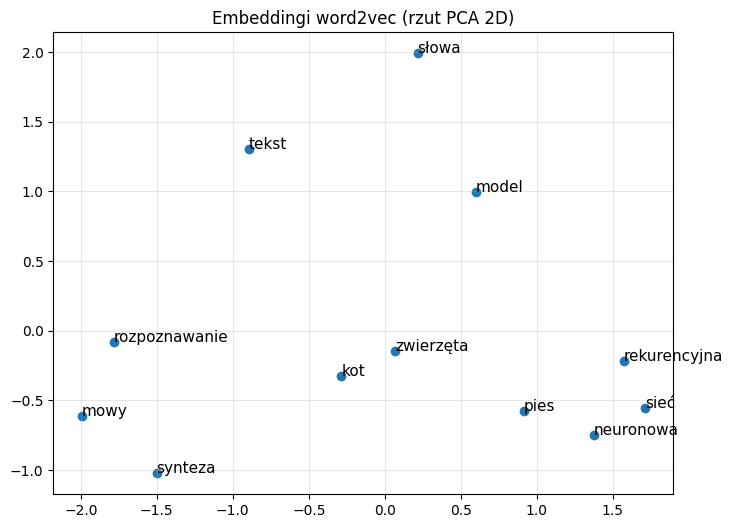

In [6]:
slowa = [w for w in ['sieć','neuronowa','rekurencyjna','model','mowy','rozpoznawanie',
        'synteza','kot','pies','zwierzęta','tekst','słowa'] if w in w2v.wv]
V = np.stack([w2v.wv[w] for w in slowa])
XY = PCA(n_components=2, random_state=0).fit_transform(V)
plt.figure(figsize=(8,6))
plt.scatter(XY[:,0], XY[:,1])
for (x,y), w in zip(XY, slowa):
    plt.annotate(w, (x,y), fontsize=11)
plt.title('Embeddingi word2vec (rzut PCA 2D)'); plt.grid(alpha=0.3); plt.show()

## 6. Mechanizm uwagi (numpy)

Dla zapytania (query) liczymy dopasowanie do słów zdania (keys), normalizujemy softmaxem
i tworzymy wektor kontekstu jako ważoną sumę.

In [7]:
def softmax(x):
    e = np.exp(x - x.max()); return e / e.sum()

zdanie = [w for w in ['mechanizm','uwagi','waży','znaczenie','słów','w','zdaniu'] if w in w2v.wv]
K = np.stack([w2v.wv[w] for w in zdanie])
q = w2v.wv['znaczenie']
scores = (K @ q) / np.sqrt(K.shape[1])
wagi = softmax(scores)
kontekst = wagi @ K

print('Uwaga dla zapytania \'znaczenie\':')
for w, a in sorted(zip(zdanie, wagi), key=lambda z:-z[1]):
    print(f'  {w:12s} {a:.3f}')
print('Wektor kontekstu, kształt:', kontekst.shape)

Uwaga dla zapytania 'znaczenie':
  znaczenie    0.183
  waży         0.160
  słów         0.160
  zdaniu       0.148
  uwagi        0.132
  mechanizm    0.131
  w            0.086
Wektor kontekstu, kształt: (50,)


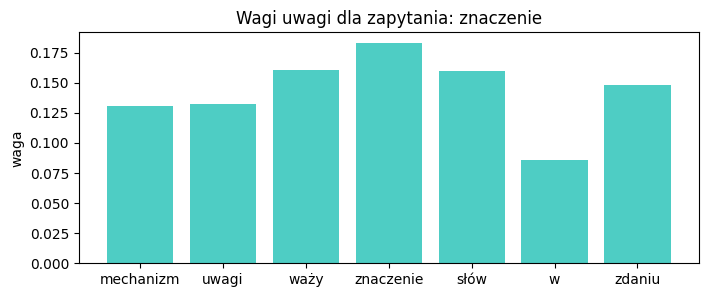

In [8]:
plt.figure(figsize=(8,3))
plt.bar(zdanie, wagi, color='#4ecdc4')
plt.title('Wagi uwagi dla zapytania: znaczenie'); plt.ylabel('waga'); plt.show()

## 7. (opcjonalnie) Realna tokenizacja modelem HerBERT

Pretrenowany tokenizer polskiego modelu pokazuje profesjonalny podział podsłowny.
Wymaga pobrania modelu (działa w Colab z dostępem do sieci).

In [9]:
# !pip -q install transformers
# from transformers import AutoTokenizer
# htok = AutoTokenizer.from_pretrained('allegro/herbert-base-cased')
# print(htok.tokenize('Przetwarzanie języka naturalnego rozpoznaje mowę.'))

## Zadanie na sprawozdanie

1. Pokaż podział BPE dla kilku form fleksyjnych wybranego wyrazu (np. pisać, piszę, napisany).
2. Wyznacz najbliższych sąsiadów 3 wybranych słów i zinterpretuj wynik.
3. Zinterpretuj rzut PCA — czy słowa z jednego tematu są blisko siebie?
4. Zbadaj wpływ rozmiaru słownika BPE (`vocab_size`) na średnią długość tokenizacji.

Format sprawozdania: `00_materialy_wspolne/szablon_sprawozdania.md`.